In [1]:
## Script for analysing the behavioural Prolific data collected for the Representations of Sentence Meaning in the Brain study
# Run with python 3.10 fMRI env
# James Fodor 2024

import pandas as pd
import numpy as np
import numpy.ma as ma
import pandas as pd
import seaborn as sns
import itertools
import matplotlib.pyplot as plt
import math

from random import choices
from scipy import stats
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import cohen_kappa_score

# load custom functions from library
import voxels_processing as vp

import warnings
warnings.filterwarnings('ignore')

C:\Users\fods1\AppData\Local\Temp\ipykernel_21924\2070615819.py:5: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
import importlib
importlib.reload(vp)

<module 'voxels_processing' from 'd:\\Code\\Python\\2023_07_Sentence_Meaning_in_the_Brain\\voxels_processing.py'>

### Load and prepare data

In [ ]:
## Load sentences and model data

# set key parameters for loading data
dataset_name = 'Fodor2024-final108' # dataset name
num_sets = 6 # the number of sets of related sentences
timing = 'mid' # start, end, mid
corr_method = 'spearman'  # spearman or pearson correlation
similarity_type = 'cosine'  # options: 'cosine' or 'diemsim'
controls_type = 1 # 1=sentence lengths only, 2=sentence lengths and minimum lengths

# load sentences set
all_sentences = np.loadtxt(dataset_name+'_sentences.txt', delimiter=';', dtype='str', encoding='utf-8')
all_sentences_indices = np.arange(len(all_sentences))
sent_pairs_all = list(itertools.combinations(all_sentences_indices, 2))
sent_pair_ids_all = np.arange(len(sent_pairs_all))
num_stimuli = all_sentences_indices.shape[0]
sent_pair_ids_diag = vp.get_pairs_in_diag(all_sentences_indices, num_sets)
similarity_subsets = {'all':sent_pair_ids_all, 'diag':sent_pair_ids_diag}

# Load model similarities
model_sims_base = 'Data-models/similarities/'
model_sims_storage = vp.load_model_sims(model_sims_base, dataset_name, normalisation=True, sim_type=similarity_type)
model_sims_storage['transformers_norml_'+similarity_type] = np.random.rand(len(sent_pair_ids_all)) # blank entry for averaged transformers so they are in the dictionary

# print summary
print('Stimuli:',num_stimuli)
print('Timing:',timing)
print('All pairs:',len(sent_pair_ids_all))
print('Diag pairs:',len(sent_pair_ids_diag))
print('Similarity type:',similarity_type)

# Load control variables
control_vars = vp.get_control_vars(controls_type, model_sims_storage)
print('Using '+str(controls_type)+' control variables')

Stimuli: 108
Timing: mid
All pairs: 5778
Diag pairs: 918
Similarity type: cosine
Using 1 control variables


In [4]:
## Load behavioural data from excel file

# Load the subjectwise Prolific Excel file
data_T_all = pd.read_excel('Data-behavioural/RSMB_all_participant_data.xlsx')

# Filter rows where Adversarial is equal to 'NADV'
data_T_diags = data_T_all[data_T_all['Type'] != 6]
data_T_nondiags = data_T_all[data_T_all['Type'] == 6]

# Prepare the rating data
data_ratings = data_T_all.iloc[:, 3:-2].values
data_ratings = data_ratings[0:-10]  # Exclude the last 10 pairs (attention check)
data_ratings = data_ratings.astype(float)  # Convert the data from string to float

# Check the dimensions
num_sentence_pairs = data_ratings.shape[0]
print('Number of sentence pairs =', num_sentence_pairs)
num_subjects = data_ratings.shape[1]
print('Number of subjects =', num_subjects)

Number of sentence pairs = 5778
Number of subjects = 486


In [5]:
## Bootstrapping of behavioural-model correlation error bars

# Initialise parameters
num_bootstraps = 100
included_subjects = np.arange(num_subjects)
samples = [choices(included_subjects, k=len(included_subjects)) for k in np.arange(num_bootstraps)]

# Perform bootstrapping
resampled_mean_sims = []
for sample in samples:
    single_resample = np.array([data_ratings[:,subject] for subject in sample]).T
    mean_single_resample = np.nanmean(single_resample,axis=1)
    resampled_mean_sims.append(mean_single_resample)
resampled_mean_sims = np.array(resampled_mean_sims)

# Initialise storage
resampled_corr_spear = {'all':{}, 'diag':{}}
resampled_corr_pear = {'all':{}, 'diag':{}}
transformers_to_average = ['ernie_12','amrbart_12','sentbert_mpnet','openai','defsent_cls']  # select which transformer models to average together
transformer_name = 'transformers_norml_'+similarity_type

# Compute bootstrapped correlations for each model
for pair in ['all','diag']:
    pair_subset = similarity_subsets[pair]
    for model_name in model_sims_storage.keys(): # loop over models
        
        # initialise model list to store bootstraps
        resampled_corr_spear[pair][model_name] = [] 
        resampled_corr_pear[pair][model_name] = []
        
        for resampled_mean_sim in resampled_mean_sims: # loop over resamples
            
            # get masked array of bootstrapped similarities
            resample_mask = ma.masked_invalid(resampled_mean_sim).mask
            resampled_mean_sim_ma = np.ma.array(resampled_mean_sim, mask=resample_mask)
            model_sims_ma = np.ma.array(model_sims_storage[model_name], mask=resample_mask)
            control_vars_ma = [np.ma.array(control_var, mask=resample_mask) for control_var in control_vars]
            
            # prepare arrays for computing partial correlations
            expr_sims = resampled_mean_sim_ma[pair_subset].compressed()
            model_sims = model_sims_ma[pair_subset].compressed()
            ctrl_sims = [control_var_ma[pair_subset].compressed() for control_var_ma in control_vars_ma]
            
            # spearman correlation
            partial_correlation = vp.simple_partial_corr(expr_sims, model_sims, ctrl_sims, method='spearman')
            resampled_corr_spear[pair][model_name].append(partial_correlation[1]) # store correlation

            # pearson correlation 
            partial_correlation = vp.simple_partial_corr(expr_sims, model_sims, ctrl_sims, method='pearson')
            resampled_corr_pear[pair][model_name].append(partial_correlation[1]) # store correlation
            
    # Add average over selected transformers
    resampled_corr_spear[pair][transformer_name] = np.mean([resampled_corr_spear[pair][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average],axis=0)
    resampled_corr_pear[pair][transformer_name] = np.mean([resampled_corr_pear[pair][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average],axis=0)
    
# Compute mean correlations
model_mean_corrs = {'all':{},'diag':{}}
for pair in model_mean_corrs.keys():
    _, _, model_mean_corrs[pair] = vp.calc_neuro_model_correlations(model_sims_storage['Prolific_rated'], model_sims_storage, control_vars, model_sims_storage.keys(), similarity_subsets[pair], method='spearman', shuffle=False)
    model_mean_corrs[pair][transformer_name] = np.mean([model_mean_corrs[pair][transformer+'_norml_'+similarity_type] for transformer in transformers_to_average],axis=0)

### Plot behavioural data

In [6]:
## Define model subsets for plotting
models_subset = 2

if models_subset==1: # main models for paper
    models_shortnames = ['conceptnet_mean_random','conceptnet_mean','transformers','conceptnet_weights-fixed_struct-low_verbnet','AMR_smatch']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Random', 'Mean-CN', 'Transformer', 'Verbnet-CN', 'AMR-Smatch']
    width_space = 0.15
    fig_width = 9
    y_max = 0.81
    subset_name = 'rsmb'
    
elif models_subset==2: # all models
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_mult_mod', 'conceptnet_conv_mod', 'glove', 'infersent', 
                         'ernie_12', 'llama3_32', 'amrbart_12', 'universal', 'defsent_cls', 'sentbert_mpnet', 'openai', 
                         'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR', 'conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN-Mean', 'CN-Mult', 'CN-Conv', 'Glove', 'Infersent',
                   'Ernie-12', 'Llama3-32', 'AMRBart-12', 'USE', 'DefSent', 'SentBERT', 'OpenAI', 
                   'S3BERT', 'Benepar-sub', 'CFG-sub', 'AMR-CN', 'AMR-Smatch', 'AMR-WLK', 'Verbnet-CN', 'GPT4']
    width_space = 0.04
    fig_width = 12
    y_max = 0.91
    subset_name = 'fullset'
    
elif models_subset==3: # hybrid versions
    models_shortnames = ['verbnet']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    width_space = -0.3
    fig_width = 9
    y_max = 0.81
    subset_name = 'hybrid'
    
elif models_subset==4: # ernie layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet', 'ernie']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    width_space = -0.6
    fig_width = 9
    y_max = 0.81
    subset_name = 'ernie'
    
elif models_subset==5: # llama 3 layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet', 'llama3']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    width_space = -0.6
    fig_width = 17
    y_max = 0.81
    subset_name = 'llama'
    
elif models_subset==6: # amrbart layers
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_weights-fixed_struct-low_verbnet', 'amrbart']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    width_space = -0.6
    fig_width = 17
    y_max = 0.81
    subset_name = 'amrbart'
print('Number of included models:',len(included_models))
print('Number of model labels:',len(model_names))

Included models: ['conceptnet_mean_norml_cosine', 'conceptnet_mult_mod_norml_cosine', 'conceptnet_conv_mod_norml_cosine', 'glove6b_norml_cosine', 'infersent_norml_cosine', 'ernie_12_norml_cosine', 'llama3_32_norml_cosine', 'amrbart_12_norml_cosine', 'universal_norml_cosine', 'defsent_cls_norml_cosine', 'sentbert_mpnet_norml_cosine', 'openai_norml_cosine', 'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR_hybrid', 'AMR_smatch', 'AMR_WLK', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated']
Number of included models: 20
Number of model labels: 20


all
 mean/transformer: diff=0.045, t=11.193, p=0.00000
 transformer/hybrid: diff=-0.090, t=-15.139, p=0.00000
 hybrid/graph: diff=-0.044, t=-6.244, p=0.00000
diag
 mean/transformer: diff=0.209, t=24.828, p=0.00000
 transformer/hybrid: diff=0.026, t=2.370, p=0.00890
 hybrid/graph: diff=-0.148, t=-13.378, p=0.00000




In [7]:
## Construct bar plots with error bars and statistical significance

# Plot graphical settings
fig = plt.figure(figsize=(1.7*len(included_models),6), dpi=600) 
sns.set(font_scale=0.7, style="darkgrid", rc={"grid.linewidth": 0.5})
fig.subplots_adjust(wspace=width_space, hspace=0.5)
errorbar_parms = {'elinewidth': 0.9, 'capthick': 0.7}
bar_x_locs = np.arange(len(included_models))
bar_width = 0.4

# Storage dictionaries for p-values
p_values_1 = {}
p_values_2 = {}
p_values_3 = {}

# Loop over all models and sentence pair sets
for subplot,subset in enumerate(['all','diag']):
    
    # Add subplot
    fig_axis = fig.add_subplot(*(2,2,subplot+1))
    print(subset)

    # Prepare data for plotting
    plot_data = [resampled_corr_spear[subset][included_model] for included_model in included_models]
    corr_means = [model_mean_corrs[subset][included_model][1] for included_model in included_models]
    conf_int = [np.percentile(resampled_corr_spear[subset][included_model],[2.5,97.5]) for included_model in included_models]
    corr_std_errs = np.ptp(conf_int,axis=1)/2
    fig_axis.bar(x=bar_x_locs, height=corr_means, width=bar_width, linewidth=0.7, yerr=corr_std_errs, error_kw=errorbar_parms, capsize=2, label='Cortex noVis')

    # Get p-values for mean-transformer difference
    diff_data = resampled_corr_spear[subset]['transformers_norml_'+similarity_type]-resampled_corr_spear[subset]['conceptnet_mean_norml_'+similarity_type]
    t_stat = np.mean(diff_data)/np.std(diff_data)
    p_values_1[subset] = 1-stats.norm.cdf(t_stat, 0, 1)
    p_values_1[subset] = min(p_values_1[subset], 1-p_values_1[subset]) # display correct p-value
    print(' mean/transformer: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_1[subset]))
    
    # Get p-values for transformer-hybrid difference
    diff_data = resampled_corr_spear[subset]['parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet']-resampled_corr_spear[subset]['transformers_norml_'+similarity_type]
    t_stat = np.mean(diff_data)/np.std(diff_data)
    p_values_2[subset] = 1-stats.norm.cdf(np.mean(diff_data)/np.std(diff_data), 0, 1)
    p_values_2[subset] = min(p_values_2[subset], 1-p_values_2[subset]) # display correct p-value
    print(' transformer/hybrid: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_2[subset]))
    
    # Bootstrapping for hybrid-smatch difference
    diff_data = np.array(resampled_corr_spear[subset]['AMR_smatch'])-resampled_corr_spear[subset]['parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet']
    t_stat = np.mean(diff_data)/np.std(diff_data)
    p_values_3[subset] = 1-stats.norm.cdf(np.mean(diff_data)/np.std(diff_data), 0, 1)
    p_values_3[subset] = min(p_values_3[subset], 1-p_values_3[subset]) # display correct p-value
    print(' hybrid/graph: diff={:.3f}, t={:.3f}, p={:.5f}'.format(np.mean(diff_data),t_stat,p_values_3[subset]))

    # Figure labels and ticks
    plt.title('Human ratings '+subset+' pairs', fontsize=11)
    fig_axis.set_ylabel('spearman correlation')
    fig_axis.set_xticks(np.arange(len(included_models)), model_names)
    fig_axis.tick_params(axis='both',pad=-1) # set distance between ticks and tick labels
    fig_axis.set_yticks(np.arange(0,y_max,0.1))
    fig_axis.set_ylim([-0.01,y_max])
    
    # Add statistical significance bars
    if models_subset==1:
        vp.barplot_annotate_brackets(1, 2, p_values_1[subset], bar_x_locs, np.array(corr_means), colour='#4c72b0', ymax=0.2, multi_test=3, fs=8, width=0.8)
        vp.barplot_annotate_brackets(2, 3, p_values_2[subset], bar_x_locs, np.array(corr_means), colour='#4c72b0', ymax=0.2, multi_test=3, fs=8, width=0.8)
        vp.barplot_annotate_brackets(3, 4, p_values_3[subset], bar_x_locs, np.array(corr_means), colour='#4c72b0', ymax=0.2, multi_test=3, fs=8, width=0.8)

# Save figure
figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str(controls_type)+'_Prolific_models-'+subset_name+'_sims-'+similarity_type+'.png'
plt.savefig(figure_name, bbox_inches='tight')
plt.show()

In [ ]:
## Table displaying all results

# Collect correlations for all models and subsets
corrs = []
for subplot,subset in enumerate(['all','diag']):
    corrs.append([model_mean_corrs[subset][included_model][1] for included_model in included_models])

# Apply the function to wrap the column headers
data_store_pd = pd.DataFrame(np.array(corrs).T, index=included_models, columns=['all','diag'])

# Display styled pandas df
df_styled = data_store_pd.style.format("{:.4f}").set_properties(**{'width': '100px'})
df_styled

,all,diag
conceptnet_mean_norml_cosine,0.5100,0.4368
conceptnet_mult_mod_norml_cosine,0.5392,0.4353
conceptnet_conv_mod_norml_cosine,0.0247,-0.0180
glove6b_norml_cosine,0.4941,0.4634
infersent_norml_cosine,0.5793,0.5502
ernie_12_norml_cosine,0.5463,0.5923
llama3_32_norml_cosine,0.5429,0.6693
amrbart_12_norml_cosine,0.5573,0.5853
universal_norml_cosine,0.5149,0.5583
defsent_cls_norml_cosine,0.5723,0.6891


In [90]:
## Define model subsets for plotting
models_subset = 2

if models_subset==1: # main models for paper
    models_shortnames = ['conceptnet_mean_norml','transformers','conceptnet_weights-fixed_struct-low_verbnet','AMR_smatch']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Mean-CN', 'Transformer', 'Verbnet-CN', 'AMR-Smatch']
    width_space = 0.15
    fig_width = 12
    y_max = 0.81
    subset_name = 'rsmb'
    
elif models_subset==2: # all models
    models_shortnames = ['conceptnet_mean_norml', 'conceptnet_mult_mod', 'conceptnet_conv_mod', 'glove', 'infersent', 
                         'ernie_12', 'llama3_32', 'amrbart_12', 'universal', 'defsent_cls', 'sentbert_mpnet', 'openai', 
                         'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR', 'conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN-Mean', 'CN-Mult', 'CN-Conv', 'Glove', 'Infersent',
                   'Ernie-12', 'Llama3-32', 'AMRBart-12', 'USE', 'DefSent', 'SentBERT', 'OpenAI', 
                   'S3BERT', 'Benepar-sub', 'CFG-sub', 'AMR-CN', 'AMR-Smatch', 'AMR-WLK', 'Verbnet-CN', 'GPT4']
    width_space = 0.04
    fig_width = 12
    y_max = 0.91
    subset_name = 'fullset'

Included models: ['conceptnet_mean_norml_cosine', 'conceptnet_mult_mod_norml_cosine', 'conceptnet_conv_mod_norml_cosine', 'glove6b_norml_cosine', 'infersent_norml_cosine', 'ernie_12_norml_cosine', 'llama3_32_norml_cosine', 'amrbart_12_norml_cosine', 'universal_norml_cosine', 'defsent_cls_norml_cosine', 'sentbert_mpnet_norml_cosine', 'openai_norml_cosine', 'S3BERT_global', 'benepar_subtree', 'CFG_subtree', 'AMR_hybrid', 'AMR_smatch', 'AMR_WLK', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated']


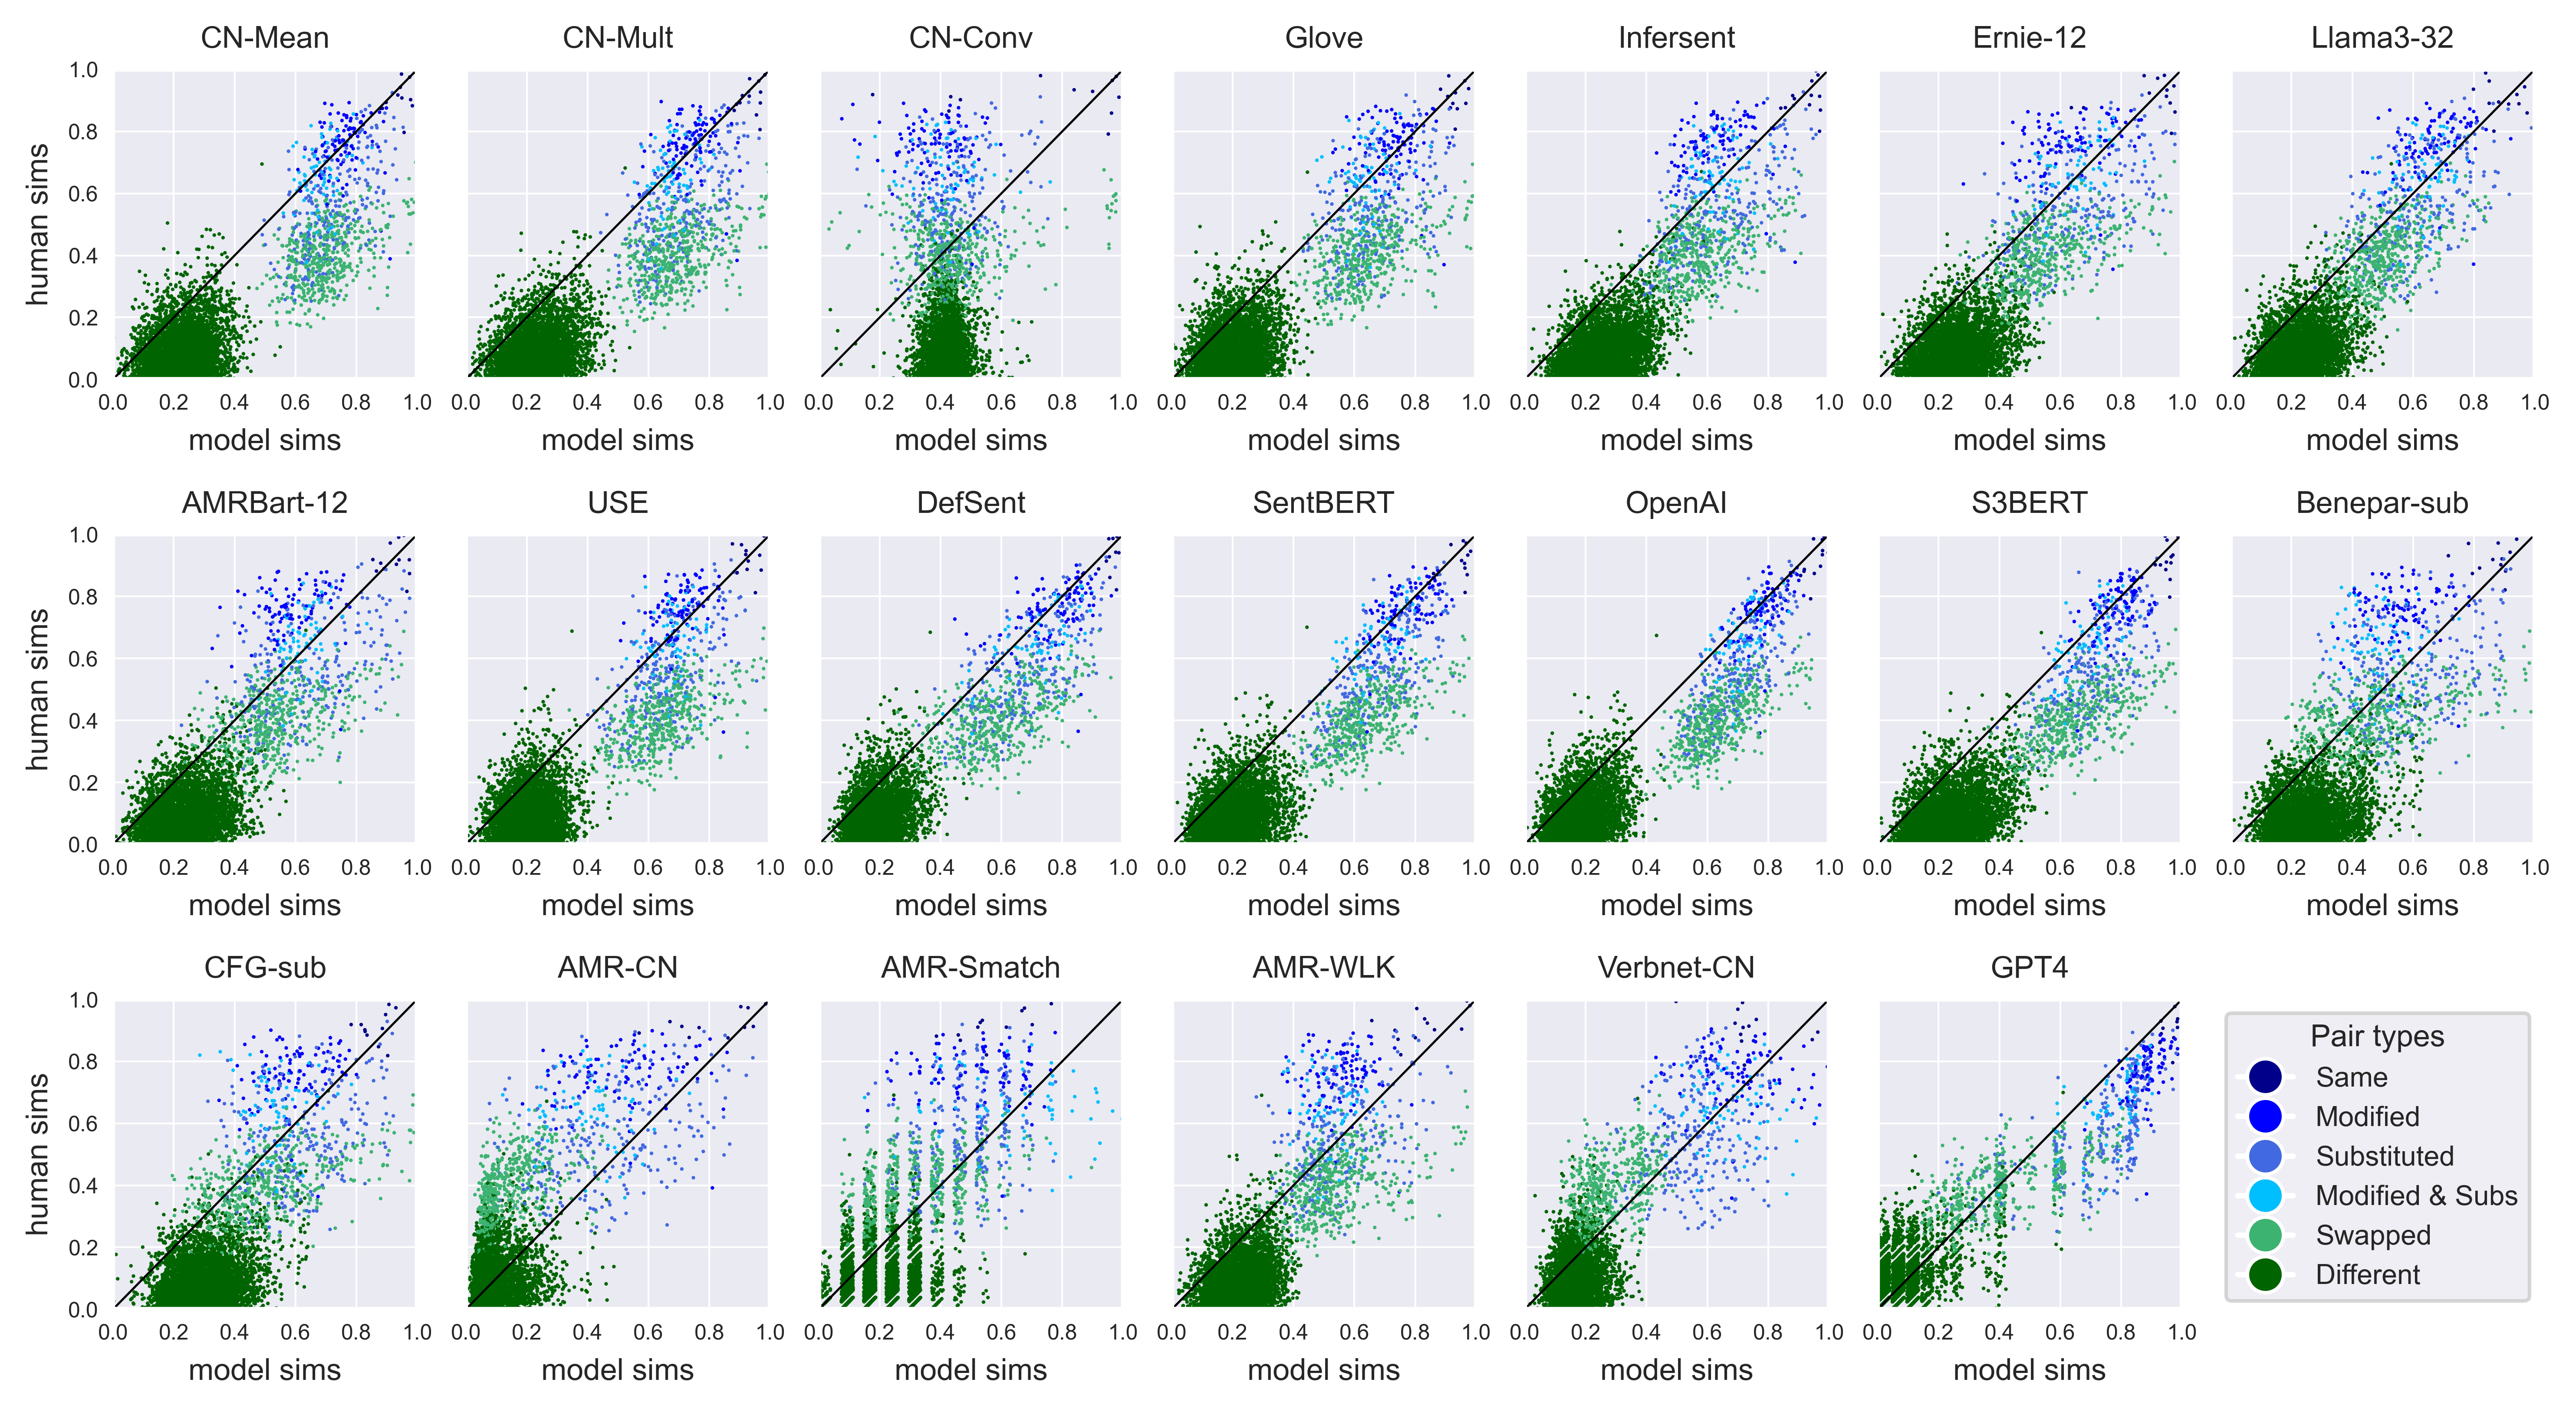

In [91]:
## Generate scatterplots of model vs experimental data

# Choose subset for analysis
sent_pairs_for_reg = sent_pair_ids_diag # sent_pair_ids_diag, sent_pair_ids_all, sent_pair_ids_balanced

# Prepare colors for type categories
type_colors = ['red', 'darkblue', 'blue','royalblue', 'deepskyblue', 'mediumseagreen', 'darkgreen']
type_labels = ['', 'Same', 'Modified', 'Substituted', 'Modified & Subs', 'Swapped', 'Different']

# Load sentpair types
sentpair_types_list = np.loadtxt('Fodor2024-final108_types-brief.txt', dtype=int)

# Normalise data for plotting
model_sims_storage_norml = vp.normalise_similarities(model_sims_storage, 0)

# Produce figure
fig = plt.figure(figsize=(fig_width,4.6*len(included_models)), facecolor='white', dpi=600)
fig.subplots_adjust(wspace=0.16, hspace=0.5)
sns.set(font_scale=0.7, rc={"grid.linewidth": 0.5}) # set font size for labels

# Loop over all models tp plot
for i,model in enumerate(included_models):
    
    # Substitute out 'openai for 'transformers' for the scatterplot:
    if 'transformers' in model:
        model = 'openai_norml_'+similarity_type  
    
    # Add a single scatterplot subplot
    figs_per_row = 7
    plot_num = (2*len(included_models),figs_per_row,i+1)
    fig_axis = fig.add_subplot(*plot_num)
    fig_axis.set_title(model_names[i]) 
    fig_axis.set_xlim(0,1)
    fig_axis.set_xticks(np.arange(0,1.01,0.2))
    fig_axis.set_ylim(0,1)
    fig_axis.tick_params(axis='both', which='major', pad=-2, labelsize=6)
    if (i % figs_per_row)==0: # add labels for every fourth row
        fig_axis.set(ylabel='human sims', xlabel='model sims')
    else: # for all other subplots
        fig_axis.set(xlabel='model sims')
        fig_axis.set_yticklabels([])

    # Add jitters for visualisation
    jit_size = 0.02
    jitters = np.random.uniform(-jit_size, jit_size, len(sent_pair_ids_all))
    ys = ((model_sims_storage_norml['Prolific_rated']+jitters).reshape(-1, 1)+jit_size)/(1+2*jit_size) # renormalise after jitter
    xs = ((model_sims_storage_norml[model]+jitters).reshape(-1, 1)+jit_size)/(1+2*jit_size) # renormalise after jitter
    mean_sq_dev = np.mean((ys-xs)**2)
   
    # Plot data
    dot_size = 1
    fig_axis.scatter(xs[sent_pair_ids_all], ys[sent_pair_ids_all], c=[type_colors[v] for v in sentpair_types_list[sent_pair_ids_all]], s=dot_size, edgecolor='none')

    # Add regression line and diagonal line
    OLS_reg = LinearRegression(fit_intercept=False).fit(xs[sent_pairs_for_reg].reshape(-1, 1), ys[sent_pairs_for_reg].reshape(-1, 1))
    plot_xs = np.arange(0,1,0.001)
    pred_ys = OLS_reg.predict(plot_xs.reshape(-1, 1))
    # plt.plot(plot_xs, pred_ys, color='red', linewidth=0.8) # add reg line
    plt.plot(plot_xs, plot_xs, color='black', linewidth=0.6) # add 45-degree line

    # Compute correlations
    actual_ys = ys[sent_pairs_for_reg].reshape(-1)
    pred_ys = OLS_reg.predict(xs[sent_pairs_for_reg].reshape(-1, 1)).reshape(-1)
    # print(model+' spearman: {:.3f}'.format(spearmanr(actual_ys, pred_ys)[0]))
    # print(model+' pearson: {:.3f}'.format(pearsonr(actual_ys, pred_ys)[0]))
    
# Add legend
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=label, markerfacecolor=color, markersize=10)
                   for color, label in zip(type_colors[1:], type_labels[1:])]
plt.legend(handles=legend_elements, title='Pair types', bbox_to_anchor=(1.1,1.0))
figure_name = 'Figures\\Fodor2024-'+timing+'_control-'+str(controls_type)+'_Prolific_models-'+subset_name+'_sims-'+similarity_type+'_scatterplots.png'
plt.savefig(figure_name, bbox_inches='tight')
plt.show()

### Split half analysis

In [ ]:
# Load the Excel file
data_T_all = pd.read_excel('Data-behavioural\RSMB_all_participant_data.xlsx')

# Filter rows where Adversarial is equal to 'NADV'
data_T_diags = data_T_all[data_T_all['Type'] != 6]
data_T_nondiags = data_T_all[data_T_all['Type'] == 6]

data_T_all

,Main ID,Type,Sentence pair,1,2,3,4,5,6,7,...,479,480,481,482,483,484,485,486,Mean,Std
0,0,1.0,The cameraman brought the new equipment to the...,NaN,NaN,NaN,7.0,NaN,NaN,NaN,...,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,6.300000,0.640312
1,1,3.0,A painter brought the equipment to the directo...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.260870,1.620987
2,2,3.0,The cameraman brought the equipment to the dir...,NaN,NaN,7.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.952381,1.838120
3,3,3.0,The cameraman brought a hot lunch for the dire...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.545455,1.437399
4,4,2.0,The cameraman brought the equipment to the dir...,NaN,NaN,6.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.090909,0.899954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5783,C5,NaN,Students suggest modern capabilities opposite ...,5.0,1.0,2.0,3.0,3.0,3.0,3.0,...,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.353909,0.825429
5784,C6,NaN,The government purchased the apartment block f...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,6.989712,0.226571
5785,C7,NaN,The reporter interviewed the lobbyist about th...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,6.977366,0.310154
5786,C8,NaN,Every day the customer watched over the displa...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,...,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,6.991770,0.143208


In [ ]:
# Function to actually perform the split-half computation
def split_half_Spearman_Brown(data, num_splits, remove_ten):
    
    # Prepare the rating data
    data_ratings = data.iloc[:, 3:-2].values
    if remove_ten==True:
        data_ratings = np.delete(data_ratings, slice(0, 10), axis=0)  # Exclude the first 10 pairs
    data_ratings = data_ratings.astype(float)  # Convert the data from string to float

    # Check the dimensions
    num_sentences = data_ratings.shape[0]
    print('Number of sentence pairs =', num_sentences)
    num_subjects = data_ratings.shape[1]
    print('Number of subjects =', num_subjects)
    
    # Compute split-half reliability with n different splits
    split_half_correls = []
    cohens_kappas = []

    for split_num in np.arange(num_splits):
        # Random split of the subjects
        idx_subjects_random = np.random.permutation(num_subjects)
        idx_subjects_group1 = idx_subjects_random[:num_subjects // 2]
        idx_subjects_group2 = idx_subjects_random[num_subjects // 2:]

        # Average rating in group 1
        data_tmp = data_ratings[:, idx_subjects_group1]
        data_mean_group1 = []
        data_mean_norm_group1 = []
        for row in data_tmp:
            tmp_data_mean = np.nanmean(row)
            tmp_data_mean_norm = (tmp_data_mean - 1) / 6  # Normalization is applied
            data_mean_group1.append(tmp_data_mean)
            data_mean_norm_group1.append(tmp_data_mean_norm)
        data_mean_group1 = np.array(data_mean_group1)
        data_mean_norm_group1 = np.array(data_mean_norm_group1)

        # Average rating in group 2
        data_tmp = data_ratings[:, idx_subjects_group2]
        data_mean_group2 = []
        data_mean_norm_group2 = []
        for row in data_tmp:
            tmp_data_mean = np.nanmean(row)
            tmp_data_mean_norm = (tmp_data_mean - 1) / 6  # Normalization is applied
            data_mean_group2.append(tmp_data_mean)
            data_mean_norm_group2.append(tmp_data_mean_norm)
        data_mean_group2 = np.array(data_mean_group2)
        data_mean_norm_group2 = np.array(data_mean_norm_group2)
        
        # Compute cohen's kappa
        data_round_group1 = np.array([math.ceil(x) if math.isnan(x)==False else 0 for x in data_mean_group1])
        data_round_group2 = np.array([math.ceil(x) if math.isnan(x)==False else 0 for x in data_mean_group2])
        cohens_kappa = cohen_kappa_score(data_round_group1, data_round_group2, weights='linear')
        cohens_kappas.append(cohens_kappa)
        
        # Correlation between groups 1 and 2
        # correl = np.corrcoef(data_mean_norm_group1, data_mean_norm_group2)[0,1]
        correl = ma.corrcoef(ma.masked_invalid(data_mean_norm_group1), ma.masked_invalid(data_mean_norm_group2))
        split_half_correls.append(correl)
        
    # Apply Spearman–Brown prediction formula
    mean_split_half_correl = np.nanmean(split_half_correls)
    corrected_mean_split_half_correl = 2*mean_split_half_correl/(1+mean_split_half_correl)
    print('Split-half correlation: {:.3f}'.format(corrected_mean_split_half_correl))
    
    mean_cohens_kappa = np.nanmean(cohens_kappas)
    corrected_mean_cohens_kappa = 2*mean_cohens_kappa/(1+mean_cohens_kappa)
    print('Cohens kappa: {:.3f}\n'.format(corrected_mean_cohens_kappa))
    
    return corrected_mean_split_half_correl, corrected_mean_cohens_kappa, split_half_correls, cohens_kappas

In [ ]:
# Compute the value for three splits of the dataset
all_msh, all_cohens, all_correls, all_cohens_kappas = split_half_Spearman_Brown(data_T_all, 100, True)
NADV_msh, NADV_cohens, NADV_correls, NADV_kappas = split_half_Spearman_Brown(data_T_nondiags, 100, True)
ADV_msh, ADV_cohens, ADV_correls, ADV_kappas = split_half_Spearman_Brown(data_T_diags, 100, False)

Number of sentence pairs = 5778
Number of subjects = 486
Split-half correlation: 0.938
Cohens kappa: 0.621

Number of sentence pairs = 4850
Number of subjects = 486
Split-half correlation: 0.715
Cohens kappa: 0.031

Number of sentence pairs = 928
Number of subjects = 486
Split-half correlation: 0.955
Cohens kappa: 0.745

